   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00


######################################################################
EASY EXERCISE
Secret string = 110
######################################################################

Classical truth table:
----------------------------------------
f(000) = 00
f(001) = 01
f(010) = 10
f(011) = 11
f(100) = 10
f(101) = 11
f(110) = 00
f(111) = 01

Verifying Simon property:
f(x) = f(x XOR s)
----------------------------------------
x=000, x XOR s=110, f(x)=00, f(x XOR s)=00, Correct=True
x=001, x XOR s=111, f(x)=01, f(x XOR s)=01, Correct=True
x=010, x XOR s=100, f(x)=10, f(x XOR s)=10, Correct=True
x=011, x XOR s=101, f(x)=11, f(x XOR s)=11, Correct=True
x=100, x XOR s=010, f(x)=10, f(x XOR

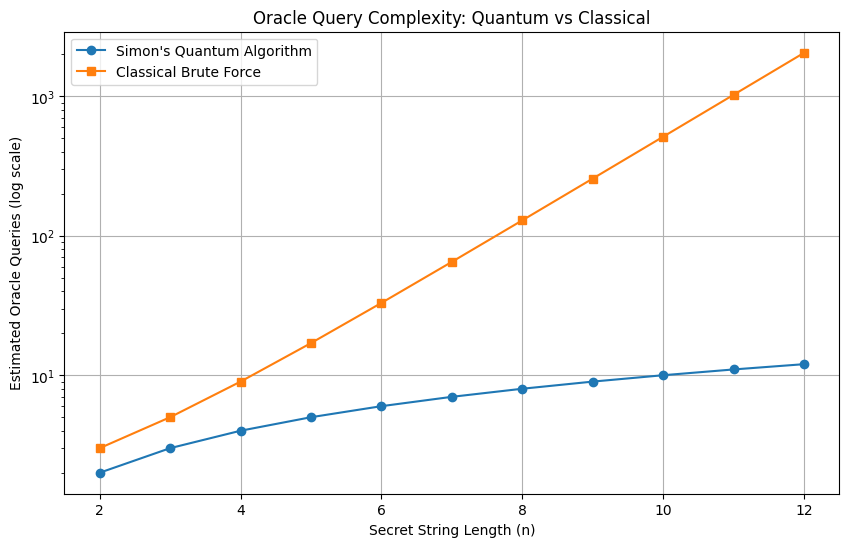

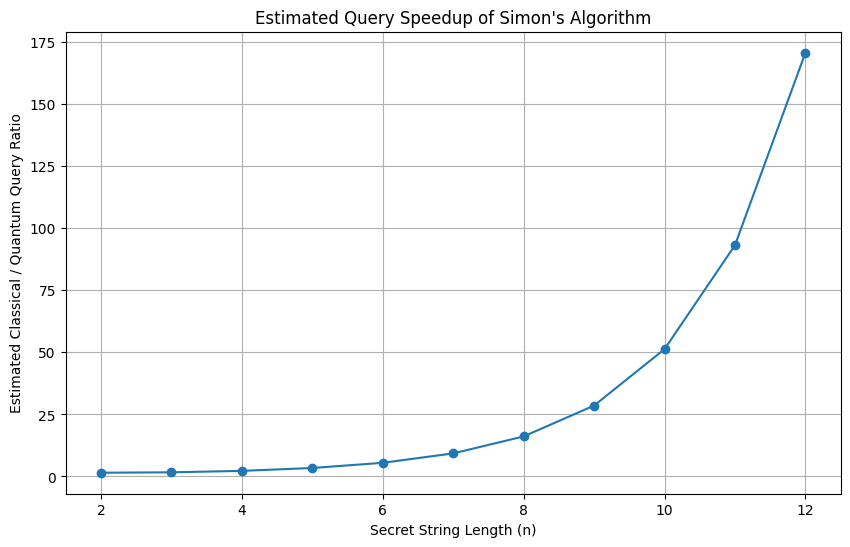




FINAL GENERALIZED DEMONSTRATION

Input Secret:     1101
Recovered Secret: 1101
Independent Equations: ['1110', '1011', '1001']
GF(2) Rank: 3

SUCCESS: Simon's algorithm recovered the hidden secret correctly.


ALL LAB EXERCISES COMPLETED

Exercises covered:

1. EASY
   - Secret: 110
   - Oracle construction
   - Truth table verification

2. MEDIUM
   - Full 3-bit Simon circuit
   - Measurement equations
   - n-1 independent equations

3. HARD
   - 4-bit secret
   - GF(2) linear system
   - Programmatic solution

4. REAL-WORLD
   - Quantum vs classical query complexity
   - Speedup calculation
   - Complexity plots

5. CHALLENGE
   - Generalized implementation
   - Any binary secret
   - All-zero edge case



In [1]:
# ============================================================
# AML23703 - QUANTUM COMPUTING LAB
# TUTORIAL 6: SIMON'S ALGORITHM
#
# Covers:
# 1. EASY       - Oracle for secret string '110' + truth table
# 2. MEDIUM     - Full Simon's algorithm for 3-bit secret
# 3. HARD       - 4-bit secret + GF(2) linear equation solving
# 4. REAL-WORLD - Oracle query comparison + speedup plot
# 5. CHALLENGE  - Generalized Simon algorithm for any secret,
#                 including the all-zero edge case
#
# GOOGLE COLAB:
# No external files or datasets need to be uploaded.
# ============================================================


# ============================================================
# STEP 1: INSTALL REQUIRED PACKAGES
# ============================================================

!pip -q install qiskit qiskit-aer matplotlib


# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from itertools import product

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator


# ============================================================
# UTILITY FUNCTIONS
# ============================================================

def bits_to_int(bits):
    """
    Convert bitstring such as '110' to integer.
    """
    return int(bits, 2)


def xor_bits(a, b):
    """
    XOR two bitstrings of equal length.
    """
    return ''.join(
        str(int(x) ^ int(y))
        for x, y in zip(a, b)
    )


def dot_mod2(a, b):
    """
    Compute dot product modulo 2.
    Example:
    a = '110'
    b = '101'

    (1*1 + 1*0 + 0*1) mod 2 = 1
    """
    return sum(
        int(x) * int(y)
        for x, y in zip(a, b)
    ) % 2


def gf2_rank(vectors):
    """
    Calculate the rank of binary vectors over GF(2).

    This is Gaussian elimination where:
    addition = XOR
    multiplication = AND
    """

    if len(vectors) == 0:
        return 0

    matrix = np.array(
        [[int(bit) for bit in row] for row in vectors],
        dtype=np.uint8
    )

    rows, cols = matrix.shape
    rank = 0

    for col in range(cols):

        pivot = None

        for row in range(rank, rows):
            if matrix[row, col] == 1:
                pivot = row
                break

        if pivot is None:
            continue

        # Swap pivot row
        matrix[[rank, pivot]] = matrix[[pivot, rank]]

        # Eliminate other rows
        for row in range(rows):
            if row != rank and matrix[row, col] == 1:
                matrix[row] ^= matrix[rank]

        rank += 1

        if rank == rows:
            break

    return rank


def solve_simon_equations(equations):
    """
    Solve:

        y . s = 0 mod 2

    for the hidden Simon string s.

    Strategy:
    - Check all possible bitstrings
    - Find which ones satisfy every measured equation
    - If only 000...0 remains, return zero
    - Otherwise return the non-zero hidden secret

    This brute-force null-space solver is excellent for
    educational 3-bit / 4-bit lab experiments.
    """

    if not equations:
        return None

    n = len(equations[0])

    candidates = []

    for candidate_tuple in product([0, 1], repeat=n):

        candidate = ''.join(map(str, candidate_tuple))

        valid = True

        for equation in equations:

            if dot_mod2(equation, candidate) != 0:
                valid = False
                break

        if valid:
            candidates.append(candidate)

    # If the only solution is zero
    if candidates == ['0' * n]:
        return '0' * n

    # For standard Simon's problem,
    # rank n-1 should leave exactly {0, s}
    non_zero = [
        x for x in candidates
        if x != '0' * n
    ]

    if len(non_zero) == 1:
        return non_zero[0]

    return {
        "candidates": candidates,
        "message": "Need more independent equations"
    }


# ============================================================
# SIMON ORACLE CONSTRUCTION
# ============================================================

def classical_simon_function(x, secret):
    """
    Construct a Simon-compatible function.

    For non-zero secret s:

        f(x) = f(x XOR s)

    We construct an (n-1)-bit function using a pivot bit.

    If s[pivot] = 1, then for every j != pivot:

        output_j = x_j XOR (s_j * x_pivot)

    The kernel of this linear mapping is exactly {0, s}.

    For secret = 000...0:
        f(x) = x
    which is one-to-one.
    """

    n = len(secret)

    # All-zero Simon edge case:
    # one-to-one function
    if secret == '0' * n:
        return x

    pivot = secret.index('1')

    output = []

    for j in range(n):

        if j == pivot:
            continue

        value = int(x[j]) ^ (
            int(secret[j]) & int(x[pivot])
        )

        output.append(str(value))

    return ''.join(output)


def create_simon_oracle(secret):
    """
    Create a quantum oracle U_f:

        |x>|y>  ->  |x>|y XOR f(x)>

    Input register:
        n qubits

    Output register:
        n qubits

    For non-zero secret, only n-1 output qubits
    are needed, but we keep n for simplicity.
    """

    n = len(secret)

    qc = QuantumCircuit(
        2 * n,
        name=f"SimonOracle_{secret}"
    )

    # ========================================================
    # CASE 1: ALL-ZERO SECRET
    #
    # f(x) = x
    #
    # Copy each input bit to corresponding output bit.
    # ========================================================

    if secret == '0' * n:

        for i in range(n):
            qc.cx(i, n + i)

        return qc


    # ========================================================
    # CASE 2: NON-ZERO SECRET
    # ========================================================

    pivot = secret.index('1')

    output_index = 0

    for j in range(n):

        if j == pivot:
            continue

        # output = x_j
        qc.cx(j, n + output_index)

        # output = output XOR x_pivot
        # only if secret[j] = 1
        if secret[j] == '1':
            qc.cx(pivot, n + output_index)

        output_index += 1

    return qc


# ============================================================
# BUILD FULL SIMON CIRCUIT
# ============================================================

def create_simon_circuit(secret):
    """
    Standard Simon's algorithm:

    1. Start with |0>|0>
    2. Apply H to input register
    3. Apply oracle U_f
    4. Measure/discard output register
    5. Apply H to input register
    6. Measure input register

    Measurement result y satisfies:

        y . s = 0 mod 2
    """

    n = len(secret)

    oracle = create_simon_oracle(secret)

    qc = QuantumCircuit(
        2 * n,
        n
    )

    # Step 1: Superposition over x
    for i in range(n):
        qc.h(i)

    # Step 2: Apply oracle
    qc.compose(
        oracle,
        inplace=True
    )

    # Step 3:
    # Apply Hadamard to input register
    for i in range(n):
        qc.h(i)

    # Step 4:
    # Measure input register
    for i in range(n):
        qc.measure(i, i)

    return qc


# ============================================================
# RUN SIMON'S ALGORITHM
# ============================================================

def run_simon(secret, shots=2048, verbose=True):
    """
    Execute Simon's algorithm and recover the secret.
    """

    n = len(secret)

    qc = create_simon_circuit(secret)

    simulator = AerSimulator()

    result = simulator.run(
        qc,
        shots=shots
    ).result()

    counts = result.get_counts()

    # --------------------------------------------------------
    # Qiskit displays classical strings in reverse bit order
    # relative to qubit indexing.
    #
    # Reverse them so they match our secret convention.
    # --------------------------------------------------------

    measurements = []

    for result_string, count in counts.items():

        corrected = result_string[::-1]

        measurements.append(
            (corrected, count)
        )

    # Sort by frequency
    measurements.sort(
        key=lambda x: x[1],
        reverse=True
    )

    # --------------------------------------------------------
    # Collect independent equations
    # --------------------------------------------------------

    independent_equations = []

    current_rank = 0

    for measurement, count in measurements:

        # Zero equation gives no information
        if measurement == '0' * n:
            continue

        trial = independent_equations + [measurement]

        new_rank = gf2_rank(trial)

        if new_rank > current_rank:

            independent_equations.append(
                measurement
            )

            current_rank = new_rank

    # --------------------------------------------------------
    # Determine secret
    # --------------------------------------------------------

    if current_rank == n:

        # Full rank means no non-zero s can be orthogonal
        # to every equation.
        recovered_secret = '0' * n

    else:

        solution = solve_simon_equations(
            independent_equations
        )

        if isinstance(solution, str):
            recovered_secret = solution
        else:
            recovered_secret = solution

    if verbose:

        print("=" * 65)
        print("SIMON'S ALGORITHM RESULTS")
        print("=" * 65)

        print(f"\nActual secret:    {secret}")
        print(f"Recovered secret: {recovered_secret}")

        print("\nIndependent measurement equations:")

        for equation in independent_equations:
            print(
                f"  {equation} . s = 0 (mod 2)"
            )

        print(
            f"\nGF(2) Rank: {current_rank}"
        )

        print("\nTop measurement counts:")

        for measurement, count in measurements[:10]:
            print(
                f"  {measurement}: {count}"
            )

        print("=" * 65)

    return {
        "secret": secret,
        "recovered_secret": recovered_secret,
        "equations": independent_equations,
        "rank": current_rank,
        "counts": counts,
        "circuit": qc
    }


# ============================================================
# EASY EXERCISE
#
# Implement Simon's oracle for secret '110'
# and verify correctness against a truth table.
# ============================================================

print("\n")
print("#" * 70)
print("EASY EXERCISE")
print("Secret string = 110")
print("#" * 70)

easy_secret = "110"

print("\nClassical truth table:")
print("-" * 40)

easy_truth_table = {}

for x_tuple in product([0, 1], repeat=len(easy_secret)):

    x = ''.join(map(str, x_tuple))

    y = classical_simon_function(
        x,
        easy_secret
    )

    easy_truth_table[x] = y

    print(
        f"f({x}) = {y}"
    )


print("\nVerifying Simon property:")
print("f(x) = f(x XOR s)")
print("-" * 40)

all_correct = True

for x in easy_truth_table:

    paired_x = xor_bits(
        x,
        easy_secret
    )

    fx = easy_truth_table[x]
    fpaired = easy_truth_table[paired_x]

    correct = fx == fpaired

    if not correct:
        all_correct = False

    print(
        f"x={x}, x XOR s={paired_x}, "
        f"f(x)={fx}, f(x XOR s)={fpaired}, "
        f"Correct={correct}"
    )


print("\nOracle verification result:")

if all_correct:
    print("PASS: Oracle satisfies Simon's hidden-period property.")
else:
    print("FAIL: Oracle does not satisfy Simon's property.")


# Display the quantum oracle circuit
easy_oracle = create_simon_oracle(
    easy_secret
)

print("\nQuantum Oracle Circuit:")
print(easy_oracle.draw())


# ============================================================
# MEDIUM EXERCISE
#
# Run full Simon algorithm for a 3-bit secret
# and collect at least n-1 independent equations.
# ============================================================

print("\n\n")
print("#" * 70)
print("MEDIUM EXERCISE")
print("3-BIT SECRET")
print("#" * 70)

medium_secret = "110"

medium_result = run_simon(
    medium_secret,
    shots=2048
)

required_equations = len(medium_secret) - 1

print(
    f"\nRequired independent equations: "
    f"{required_equations}"
)

print(
    f"Collected independent equations: "
    f"{len(medium_result['equations'])}"
)

if medium_result["rank"] >= required_equations:
    print("PASS: At least n-1 independent equations collected.")
else:
    print("WARNING: Not enough independent equations.")


# ============================================================
# HARD EXERCISE
#
# Extend to a 4-bit secret and solve equations over GF(2).
# ============================================================

print("\n\n")
print("#" * 70)
print("HARD EXERCISE")
print("4-BIT SECRET + GF(2) SOLVING")
print("#" * 70)

hard_secret = "1011"

hard_result = run_simon(
    hard_secret,
    shots=4096
)

print("\nGF(2) Linear System:")

for equation in hard_result["equations"]:

    equation_text = " + ".join(
        f"s{i}"
        for i, bit in enumerate(equation)
        if bit == "1"
    )

    if equation_text == "":
        equation_text = "0"

    print(
        f"{equation} -> {equation_text} = 0 (mod 2)"
    )


print("\nFinal comparison:")
print(
    f"Actual secret    = {hard_secret}"
)
print(
    f"Recovered secret = {hard_result['recovered_secret']}"
)

if hard_result["recovered_secret"] == hard_secret:
    print("PASS: 4-bit secret correctly recovered.")
else:
    print("WARNING: Run again if insufficient equations were sampled.")


# ============================================================
# CHALLENGE EXERCISE
#
# Generalized Simon algorithm:
# - Accepts any secret bitstring
# - Automatically determines it
# - Handles all-zero edge case
# ============================================================

print("\n\n")
print("#" * 70)
print("CHALLENGE EXERCISE")
print("GENERALIZED SIMON'S ALGORITHM")
print("#" * 70)


def generalized_simon(secret, shots=4096):
    """
    General-purpose Simon solver.

    Input:
        Any binary secret string

    Examples:
        '1'
        '101'
        '1100'
        '10101'
        '0000'

    Output:
        Recovered secret
    """

    # Validate input
    if not isinstance(secret, str):
        raise ValueError(
            "Secret must be a binary string."
        )

    if len(secret) == 0:
        raise ValueError(
            "Secret cannot be empty."
        )

    if any(bit not in "01" for bit in secret):
        raise ValueError(
            "Secret must contain only 0 and 1."
        )

    result = run_simon(
        secret,
        shots=shots,
        verbose=False
    )

    return result


test_secrets = [
    "1",
    "10",
    "101",
    "110",
    "1011",
    "11001",
    "000",
    "0000"
]

print("\nTesting generalized algorithm:")

for secret in test_secrets:

    result = generalized_simon(
        secret,
        shots=4096
    )

    recovered = result[
        "recovered_secret"
    ]

    status = (
        "PASS"
        if recovered == secret
        else "CHECK"
    )

    print(
        f"Secret: {secret:>5} | "
        f"Recovered: {str(recovered):>5} | "
        f"{status}"
    )


# ============================================================
# REAL-WORLD EXERCISE
#
# Compare Simon's algorithm oracle-query requirement
# with classical brute-force search for varying n.
#
# Theoretical comparison:
#
# Simon quantum:
# approximately O(n) oracle queries
#
# Classical deterministic:
# approximately O(2^(n/2)) to O(2^n),
# depending on collision-search strategy.
#
# Here we use:
#
# Classical brute-force upper-bound style comparison:
# 2^(n-1) + 1 queries
#
# Quantum Simon estimate:
# n-1 useful independent equations
# ============================================================

print("\n\n")
print("#" * 70)
print("REAL-WORLD EXERCISE")
print("QUANTUM VS CLASSICAL ORACLE QUERY COMPARISON")
print("#" * 70)


def quantum_query_estimate(n):
    """
    Simon requires approximately n independent
    measurements/oracle calls to determine s.
    """

    if n == 1:
        return 1

    return n


def classical_query_estimate(n):
    """
    Deterministic brute-force comparison estimate.

    In the worst case, exponential queries are needed
    to guarantee finding a hidden collision.

    We use:
        2^(n-1) + 1
    """

    return (2 ** (n - 1)) + 1


string_lengths = list(
    range(2, 13)
)

quantum_queries = [
    quantum_query_estimate(n)
    for n in string_lengths
]

classical_queries = [
    classical_query_estimate(n)
    for n in string_lengths
]

speedups = [
    c / q
    for c, q in zip(
        classical_queries,
        quantum_queries
    )
]


# Print table
print(
    "\n{:>5} | {:>18} | {:>18} | {:>12}".format(
        "n",
        "Quantum Queries",
        "Classical Queries",
        "Speedup"
    )
)

print("-" * 65)

for n, q, c, s in zip(
    string_lengths,
    quantum_queries,
    classical_queries,
    speedups
):

    print(
        "{:>5} | {:>18} | {:>18} | {:>12.2f}x".format(
            n,
            q,
            c,
            s
        )
    )


# ============================================================
# PLOT 1: QUERY COMPLEXITY
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    string_lengths,
    quantum_queries,
    marker="o",
    label="Simon's Quantum Algorithm"
)

plt.plot(
    string_lengths,
    classical_queries,
    marker="s",
    label="Classical Brute Force"
)

plt.yscale("log")

plt.xlabel(
    "Secret String Length (n)"
)

plt.ylabel(
    "Estimated Oracle Queries (log scale)"
)

plt.title(
    "Oracle Query Complexity: Quantum vs Classical"
)

plt.grid(True)

plt.legend()

plt.show()


# ============================================================
# PLOT 2: SPEEDUP
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    string_lengths,
    speedups,
    marker="o"
)

plt.xlabel(
    "Secret String Length (n)"
)

plt.ylabel(
    "Estimated Classical / Quantum Query Ratio"
)

plt.title(
    "Estimated Query Speedup of Simon's Algorithm"
)

plt.grid(True)

plt.show()


# ============================================================
# FINAL DEMONSTRATION
# ============================================================

print("\n\n")
print("=" * 70)
print("FINAL GENERALIZED DEMONSTRATION")
print("=" * 70)

final_secret = "1101"

final_result = generalized_simon(
    final_secret,
    shots=8192
)

print(
    f"\nInput Secret:     {final_secret}"
)

print(
    f"Recovered Secret: {final_result['recovered_secret']}"
)

print(
    f"Independent Equations: "
    f"{final_result['equations']}"
)

print(
    f"GF(2) Rank: "
    f"{final_result['rank']}"
)

if final_result["recovered_secret"] == final_secret:

    print(
        "\nSUCCESS: Simon's algorithm recovered "
        "the hidden secret correctly."
    )

else:

    print(
        "\nRun again with more shots if required."
    )


print("\n")
print("=" * 70)
print("ALL LAB EXERCISES COMPLETED")
print("=" * 70)
print("""
Exercises covered:

1. EASY
   - Secret: 110
   - Oracle construction
   - Truth table verification

2. MEDIUM
   - Full 3-bit Simon circuit
   - Measurement equations
   - n-1 independent equations

3. HARD
   - 4-bit secret
   - GF(2) linear system
   - Programmatic solution

4. REAL-WORLD
   - Quantum vs classical query complexity
   - Speedup calculation
   - Complexity plots

5. CHALLENGE
   - Generalized implementation
   - Any binary secret
   - All-zero edge case
""")